### **Setup (only for this file)**
These lines repeat section 1 and the groups of 2.2. They are removed when Part 2 is joined to the main notebook.

In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

train_path=os.path.join("..","data","raw","train.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

df_train= pd.read_csv(train_path,index_col="ID",sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

target_col = "repeat_purchase_90d"
var_groups = {
    "Current transaction (financial)": ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
                                        "Total Desc_ Global", "Total Desc_ Linha", "Custo"],
    "Current transaction (operational)": ["N_ Detalhes", "invoice_count_current_purchase"],
    "Customer historical summary": ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
                                    "prior_mean_purchase_value", "prior_std_purchase_value",
                                    "prior_min_purchase_value", "prior_max_purchase_value"],
    "Customer cadence & gaps": ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"],
    "Rolling windows (RFM)": ["purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
                              "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d"],
}

### **12. Pre-processing: How We Decide**

In Part 1 we found the problems of the data and we wrote a plan for each one (3.7 and section 11). In Part 2 we apply this plan, but not blindly: most problems have more than one reasonable solution (fill a missing value with the median or with the mean, keep an outlier or remove it...), so we test the options and keep the one that works best, like in the classes. When the test can not separate the options, we decide by principle and choose the simpler one.

All the decisions belong to one of two layers:
* **Layer A (row by row)**: corrections that only use the values of the same row, like recomputing a mean as total / count. They learn nothing from the other rows, so they can be applied to the whole file, and later to test.csv, without leakage.
* **Layer B (learned from the data)**: steps that learn something from the rows they see, like the median used to fill the missing values, the levels of a category or the mean of a scaler. They go inside a scikit-learn `Pipeline`, so in each split they are fitted only on the train rows. test.csv is never used to fit them.

Before testing anything, we fix how we test: which rows (12.1), how they are split (12.2) and how each option is measured (12.3).

In [3]:
import warnings
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, FunctionTransformer,
                                   StandardScaler, MinMaxScaler, RobustScaler)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# without scaling the solver can stop at its limit of iterations. We look at this in section 18, so we hide the warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

#### **12.1. Development and Holdout Rows**

First we apply the decision of 3.1: the 65 empty rows are removed. They are removed only from train.csv, because test.csv can not lose rows (every ID needs a prediction).

Then the most recent purchases (2024 and 2025) are kept apart as a **holdout**. No decision of Part 2 or Part 3 looks at them, so in Part 4 they can give an honest check of the final model on purchases it never saw. All the tests of Part 2 only use the development rows (2015 to 2023).

In [4]:
# Part 2 starts again from the raw file. The empty rows of 3.1 are removed here, only from train.csv
# (test.csv can not lose rows: every ID needs a prediction)
empty_rows = df_train.drop(columns=["customer_id", target_col]).isna().all(axis=1)
df_base = df_train.loc[~empty_rows].copy()
df_base["purchase_date"] = pd.to_datetime(df_base["purchase_date"])
print(f"Empty rows removed: {empty_rows.sum()}")

# the purchases of 2024 and 2025 stay apart for the final evaluation in Part 4
is_dev = df_base["purchase_date"] < "2024-01-01"
print(f"Rows: {len(df_base):,} | Development (2015-2023): {is_dev.sum():,} | Holdout (2024-2025): {(~is_dev).sum():,}")
print(f"Repeat rate | Development: {df_base.loc[is_dev, target_col].mean():.3f} | Holdout: {df_base.loc[~is_dev, target_col].mean():.3f}")

Empty rows removed: 65
Rows: 6,469 | Development (2015-2023): 5,634 | Holdout (2024-2025): 835
Repeat rate | Development: 0.553 | Holdout: 0.605


The holdout has 835 purchases. Its repeat rate (0.605) is higher than in the development rows (0.553), which is the change over time we saw in section 5. This is one more reason to keep it apart: it is the most recent part of the data, so it is the closest thing we have to the future purchases the model will predict.

#### **12.2. Temporal Splits**

In section 5 we saw that the model will always predict the future and that the data changes over time. A random split (`train_test_split`) would mix past and future purchases, and the scores would be too optimistic. So we use **temporal splits**: the development rows are cut into validation blocks of 6 months, and each block is predicted by a model trained only on older purchases.

There is one more detail. The target looks 90 days ahead: a purchase made 30 days before a validation block gets its target from what happens inside the block. If this purchase was in the train rows, the model would learn from the future. So we leave a **gap of 90 days** between the train rows and the validation block.

The same client can appear in the train rows and in the validation block. This is not leakage, it is what happens in real use: in section 5, almost 90% of the recent purchases came from clients that already bought before.

In [5]:
# 12 validation blocks of 6 months, from 2018 to 2023. Each block is predicted by a model trained
# only on the purchases made more than 90 days before the block starts.
dev = df_base.loc[is_dev]
block_starts = pd.date_range("2018-01-01", "2023-07-01", freq="6MS")

folds = []
for start in block_starts:
    end = start + pd.DateOffset(months=6)
    train_idx = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    val_idx = dev.index[(dev["purchase_date"] >= start) & (dev["purchase_date"] < end)]
    folds.append((train_idx, val_idx))

pd.DataFrame({
    "validation block": [f"{s:%Y-%m} to {s + pd.DateOffset(months=5):%Y-%m}" for s in block_starts],
    "train rows": [len(t) for t, v in folds],
    "validation rows": [len(v) for t, v in folds],
    "repeat rate (validation)": [round(dev.loc[v, target_col].mean(), 3) for t, v in folds],
}, index=[f"fold {i + 1}" for i in range(len(folds))])

,validation block,train rows,validation rows,repeat rate (validation)
fold 1,2018-01 to 2018-06,1186,292,0.534
fold 2,2018-07 to 2018-12,1624,424,0.540
fold 3,2019-01 to 2019-06,1909,232,0.517
fold 4,2019-07 to 2019-12,2287,414,0.524
fold 5,2020-01 to 2020-06,2578,293,0.577
fold 6,2020-07 to 2020-12,2962,377,0.607
fold 7,2021-01 to 2021-06,3234,315,0.581
fold 8,2021-07 to 2021-12,3649,467,0.527
fold 9,2022-01 to 2022-06,4004,269,0.539
fold 10,2022-07 to 2022-12,4392,359,0.437


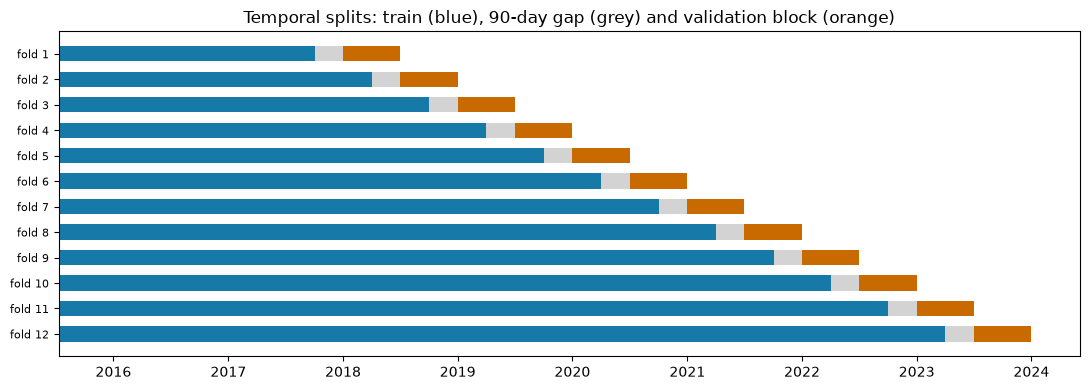

In [6]:
# picture of the 12 splits
first_day = dev["purchase_date"].min()
fig, ax = plt.subplots(figsize=(11, 4))
for i, start in enumerate(block_starts):
    gap_start = start - pd.Timedelta(days=90)
    end = start + pd.DateOffset(months=6)
    ax.barh(i, (gap_start - first_day).days, left=0, color="#1779A8", height=0.6)
    ax.barh(i, 90, left=(gap_start - first_day).days, color="lightgrey", height=0.6)
    ax.barh(i, (end - start).days, left=(start - first_day).days, color="#C96A00", height=0.6)
years = pd.date_range("2016-01-01", "2024-01-01", freq="YS")
ax.set_xticks([(y - first_day).days for y in years])
ax.set_xticklabels([y.year for y in years])
ax.set_yticks(range(len(block_starts)))
ax.set_yticklabels([f"fold {i + 1}" for i in range(len(block_starts))], fontsize=8)
ax.invert_yaxis()
ax.set_title("Temporal splits: train (blue), 90-day gap (grey) and validation block (orange)")
plt.tight_layout()
plt.show()

We get 12 splits. The train rows grow from 1,186 (fold 1) to 5,077 (fold 12), as in real use the model always learns from all the past. Each validation block has between 232 and 467 purchases, and the repeat rate of the blocks goes from 0.437 to 0.607, so some periods are harder than others. This is why every option is always compared on the **same** 12 splits.

#### **12.3. The Measuring Instrument**

To compare the options we need a model that is fast and that reacts to the pre-processing. Like in the classes, we use a **logistic regression**: it is sensitive to the scale, the skewness and the encoding of the variables, which is exactly what we want to measure (a tree would not see most of these differences). It is a measuring instrument, not the final model: the models are chosen in Part 4.

The functions below build the instrument:
* `make_preprocessor` builds Layer B with one option for each decision (how to fill the missing values, how to treat the long tails, how to encode the categories, which scaler). Each section changes only one of these options.
* `temporal_scores` fits the pipeline on the train rows of each split and scores its validation block, so each option gets **12 scores**.
* `compare` puts the options side by side. Both options are scored on the same 12 splits, so we compute their difference fold by fold (a **paired** comparison) and the standard error of this difference (SEM). When the mean difference is smaller than 2 SEM, we say it is **inside the noise**: with this data the two options can not be separated.

The folds share part of their train rows, so they are not fully independent and the SEM is a bit optimistic. This is one more reason to only trust the clear differences.

In [7]:
def signed_log(X):
    """log1p that keeps the sign. For values >= 0 it is the same as log1p, and it also works
    on the negative impossible values of the option "keep as is" (13.4)."""
    return np.sign(X) * np.log1p(np.abs(X))


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to its 1% and 99% quantiles, learned on the train rows."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, 0.01, axis=0)
        self.high_ = np.nanquantile(X, 0.99, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


def make_preprocessor(log_cols, plain_cols, cat_cols, flag_cols=(), num_fill="median", indicators=False,
                      cat_fill="Missing", outliers="log1p", encoder="onehot", min_frequency=None, scaler="standard"):
    """Layer B: the steps that learn something from the data (medians, levels, scales).
    Inside a Pipeline they are fitted only on the train rows of each split."""
    scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

    def numeric_steps(long_tail):
        if num_fill == "zero":
            steps = [("impute", SimpleImputer(strategy="constant", fill_value=0, add_indicator=indicators))]
        else:
            steps = [("impute", SimpleImputer(strategy=num_fill, add_indicator=indicators))]
        if long_tail and outliers == "log1p":
            steps.append(("log", FunctionTransformer(signed_log)))
        elif long_tail and outliers == "winsorize":
            steps.append(("winsorize", Winsorizer()))
        if scaler in scalers:
            steps.append(("scale", scalers[scaler]()))
        return Pipeline(steps)

    # categories: missing -> "Missing" (or the most frequent level), then encoding
    if cat_fill == "Missing":
        cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value="Missing"))]
    else:
        cat_steps = [("impute", SimpleImputer(strategy="most_frequent"))]
    if encoder == "onehot" and min_frequency is None:
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    elif encoder == "onehot":
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                                  sparse_output=False)))
    else:
        cat_steps.append(("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)))
        if scaler in scalers:
            cat_steps.append(("scale", scalers[scaler]()))

    parts = [("log", numeric_steps(long_tail=True), list(log_cols)),       # money, counts and days (long tails)
             ("plain", numeric_steps(long_tail=False), list(plain_cols)),  # columns that can be negative, or ratios
             ("cat", Pipeline(cat_steps), list(cat_cols)),
             ("flags", "passthrough", list(flag_cols))]                    # 0/1 columns
    return ColumnTransformer([p for p in parts if len(p[2]) > 0])

In [8]:
def temporal_scores(frame, columns, recipe, row_filter=None, metric="ap"):
    """One score per fold: the instrument is fitted on the train rows and scored on the validation block."""
    used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
    scores = []
    for train_idx, val_idx in folds:
        train, val = frame.loc[train_idx], frame.loc[val_idx]
        if row_filter is not None:
            train = row_filter(train)   # rows are only removed from the train side, never from validation
        pipe = Pipeline([("prep", make_preprocessor(**columns, **recipe)),
                         ("model", LogisticRegression(max_iter=3000))])
        pipe.fit(train[used], train[target_col])
        prob = pipe.predict_proba(val[used])[:, 1]
        if metric == "ap":
            scores.append(average_precision_score(val[target_col], prob))
        elif metric == "f1":
            scores.append(f1_score(val[target_col], prob >= 0.5))
        else:
            scores.append((prob >= 0.5).mean())   # share of rows predicted as 1
    return np.array(scores)


def compare(results, reference):
    """Mean AP of each option and its difference to the reference, fold by fold (paired)."""
    rows = {}
    for name, scores in results.items():
        diff = scores - results[reference]
        sem = diff.std(ddof=1) / np.sqrt(len(diff))
        if name == reference:
            verdict = "reference"
        elif abs(diff.mean()) <= 2 * sem:
            verdict = "inside the noise"
        else:
            verdict = "better" if diff.mean() > 0 else "worse"
        rows[name] = {"AP": round(scores.mean(), 4), "difference": round(diff.mean(), 4), "SEM": round(sem, 4),
                      "better in": f"{(diff > 0).sum()}/{len(diff)}", "verdict": verdict}
    return pd.DataFrame(rows).T

The instrument uses the numeric and categorical columns of 2.2. `ID`, `customer_id` and `purchase_date` are not used as variables: `ID` is the number of the row and `customer_id` is only the key to join `clientes.csv` (section 10), and `purchase_date` is only used to build the temporal splits (section 5).

Which score do we compare? The competition uses the F1 of class 1, but the F1 needs a threshold (predict 1 when the probability is above it), and the threshold is a decision of Part 4 (2.3). Lets see what the F1 with the default threshold of 0.5 says, next to the floor of always predicting 1 and the **average precision (AP)**.

In [9]:
# columns of the instrument at the start (clientes.csv and the new features come in sections 19 and 20)
# not used as variables: ID (index, section 10), customer_id (only the key for clientes.csv, section 10)
# and purchase_date (only used to build the temporal splits, section 5)
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])
cat_cols = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse", "document_series"]
columns = {"log_cols": numeric_cols, "plain_cols": ["random_noise"], "cat_cols": cat_cols, "flag_cols": []}

# the starting recipe: usual defaults. Each section below tests one of these choices.
recipe = {"num_fill": "median", "indicators": False, "cat_fill": "Missing", "outliers": "log1p",
          "encoder": "onehot", "min_frequency": None, "scaler": "standard"}

# first version of the data: the impossible values of 3.6 only set to missing (section 13 decides properly)
df_start = df_base.copy()
for col in ["prior_mean_purchase_value", "spend_365d"]:
    df_start.loc[(df_start[col] < 0) | (df_start[col] >= 1e8), col] = np.nan
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    df_start.loc[df_start[col] < 0, col] = np.nan

f1_05 = temporal_scores(df_start, columns, recipe, metric="f1")
share_1 = temporal_scores(df_start, columns, recipe, metric="share")
ap_start = temporal_scores(df_start, columns, recipe)
rate = np.array([dev.loc[v, target_col].mean() for t, v in folds])
pd.DataFrame({"repeat rate": rate, "predicted as 1 (at 0.5)": share_1, "F1 always 1": 2 * rate / (1 + rate),
              "F1 at 0.5": f1_05, "AP": ap_start}, index=[f"fold {i + 1}" for i in range(12)]).T.round(3)

,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,fold 10,fold 11,fold 12
repeat rate,0.534,0.540,0.517,0.524,0.577,0.607,0.581,0.527,0.539,0.437,0.563,0.596
predicted as 1 (at 0.5),0.702,0.519,0.616,0.505,0.567,0.576,0.473,0.422,0.669,0.421,0.469,0.528
F1 always 1,0.696,0.701,0.682,0.688,0.732,0.756,0.735,0.690,0.700,0.609,0.720,0.747
F1 at 0.5,0.737,0.713,0.776,0.751,0.699,0.749,0.723,0.722,0.757,0.656,0.705,0.752
AP,0.850,0.803,0.864,0.859,0.792,0.838,0.851,0.852,0.849,0.747,0.844,0.879


In [10]:
print(f"F1 of always predicting 1: {(2 * rate / (1 + rate)).mean():.3f}")
print(f"F1 of the model at 0.5:    {f1_05.mean():.3f} (above always 1 in {(f1_05 > 2 * rate / (1 + rate)).sum()} of 12 folds)")
print(f"AP of always predicting 1: {rate.mean():.3f} (the AP of a model with no information is the repeat rate)")
print(f"AP of the model:           {ap_start.mean():.3f}")

F1 of always predicting 1: 0.705
F1 of the model at 0.5:    0.728 (above always 1 in 8 of 12 folds)
AP of always predicting 1: 0.545 (the AP of a model with no information is the repeat rate)
AP of the model:           0.836


At 0.5 the instrument is only a little better than always predicting 1 (F1 of 0.728 vs 0.705), and it is better in only 8 of the 12 folds. The reason is in the second line: the share of purchases predicted as 1 jumps between 42% and 70% from fold to fold, and the F1 moves with it. So with the F1 at 0.5 we would mostly measure where the threshold falls, not how good the pre-processing is.

So to compare the options of Part 2 we use the **average precision (AP)**, the area under the precision-recall curve. It looks at all the thresholds at once, it is about class 1 (the same class as the F1 of the competition), and it only depends on how well the model **ranks** the purchases. A model with no information has an AP equal to the repeat rate (0.545), and the instrument gets 0.836. The F1 comes back in Part 4, when the threshold is tuned.

### **13. Impossible Values and Values That Can Be Recovered**

In 3.6 we found the impossible values (1e9, negative values, gaps of -4 days, inflated means and maximums) and the rules that recover some missing values exactly (3.6.7). Here we put these corrections in two functions (13.1), and we test if correcting the values is really better than keeping them or dropping the rows (13.2).

#### **13.1. The Correction Functions**

`blank_impossible` sets to missing all the impossible values of 3.6, and `recover_values` (3.6.7) fills the cells that can be computed exactly. Both are Layer A: each row is corrected only with its own values, so they can be applied to test.csv in the same way.

In [11]:
def blank_impossible(frame):
    """Impossible values of 3.6 -> missing. It works row by row, so it learns nothing from the other rows."""
    out = frame.copy()
    count = out["prior_purchase_count"]
    # 3.6.1 to 3.6.3: 1e9, negative values, means bigger than the biggest purchase, spend_365d bigger than the prior spend
    mean = out["prior_mean_purchase_value"]
    out.loc[(mean < 0) | (mean >= 1e8) | (mean > out["prior_max_purchase_value"] + 0.01), "prior_mean_purchase_value"] = np.nan
    spend = out["spend_365d"]
    out.loc[(spend < 0) | (spend >= 1e8) | (spend > out["prior_total_spend"] + 0.01), "spend_365d"] = np.nan
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        out.loc[out[col] < 0, col] = np.nan
    # 3.6.6: biggest purchase above its limit
    max_limit = out["prior_total_spend"] - (count - 1) * out["prior_min_purchase_value"]
    out.loc[(count >= 1) & (out["prior_max_purchase_value"] > max_limit + 0.01), "prior_max_purchase_value"] = np.nan
    return out

def recover_values(frame):
    """Fills the cells that can be computed exactly from other columns of the same row (3.6.1 and 3.6.7)."""
    out = frame.copy()
    count, tenure = out["prior_purchase_count"], out["customer_tenure_days"]
    out["prior_mean_purchase_value"] = out["prior_total_spend"] / count.replace(0, np.nan)

    days, gap = out["days_since_previous_purchase"].copy(), out["prior_mean_gap_days"].copy()
    fill = days.isna() & (count == 1)
    out.loc[fill, "days_since_previous_purchase"] = tenure[fill]
    fill = days.isna() & (count >= 2) & gap.notna()
    out.loc[fill, "days_since_previous_purchase"] = (tenure - gap * (count - 1))[fill]
    fill = gap.isna() & (count >= 2) & days.notna()
    out.loc[fill, "prior_mean_gap_days"] = ((tenure - days) / (count - 1))[fill]

    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == 0)
    out.loc[fill, "spend_365d"] = 0.0
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == out["purchase_count_180d"])
    out.loc[fill, "spend_365d"] = out.loc[fill, "spend_180d"]
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == count)
    out.loc[fill, "spend_365d"] = out.loc[fill, "prior_total_spend"]

    fill = out["prior_max_purchase_value"].isna() & (count == 1)
    out.loc[fill, "prior_max_purchase_value"] = out.loc[fill, "prior_total_spend"]
    fill = out["prior_max_purchase_value"].isna() & (count == 2)
    out.loc[fill, "prior_max_purchase_value"] = (out["prior_total_spend"] - out["prior_min_purchase_value"])[fill]
    return out

df_blank = blank_impossible(df_base)
df_recovered = recover_values(df_blank)
changed = pd.DataFrame({"missing in the file": df_base[numeric_cols].isna().sum(),
                        "after blanking the impossible values": df_blank[numeric_cols].isna().sum(),
                        "after recovering": df_recovered[numeric_cols].isna().sum()})
print(f"Cells set to missing: {(changed.iloc[:, 1] - changed.iloc[:, 0]).sum()} | Cells recovered: {(changed.iloc[:, 1] - changed.iloc[:, 2]).sum()}")
print(f"Missing cells | in the file: {changed.iloc[:, 0].sum():,} | after the two functions: {changed.iloc[:, 2].sum():,}")
changed[changed.iloc[:, 1] != changed.iloc[:, 2]]

Cells set to missing: 224 | Cells recovered: 787
Missing cells | in the file: 6,698 | after the two functions: 6,135


,missing in the file,after blanking the impossible values,after recovering
prior_mean_purchase_value,797,874,603
prior_max_purchase_value,603,649,645
days_since_previous_purchase,796,812,611
prior_mean_gap_days,1243,1259,1056
spend_365d,195,264,156


Setting the impossible values to missing creates 224 missing cells, and the recovery fills 787, so after the two functions there are fewer missing values than in the original file (6,135 against 6,698). `prior_mean_purchase_value` is now missing only in the first purchases (no history), and `spend_365d` goes from 264 to 156 missing values.

#### **13.2. Which Treatment?**

Is it worth it? We compare four ways to treat the impossible values: keep them as they are, set them to missing (the plan of 3.6), set them to missing and recover what can be computed (13.1), and drop the rows that have an impossible value. A row is only dropped from the train rows: the validation rows stay, because in test.csv every purchase needs a prediction.

In [12]:
# rows with at least one impossible value (for the arm "drop the row")
had_impossible = (df_blank[numeric_cols].isna() & df_base[numeric_cols].notna()).any(axis=1)
print(f"Rows with at least one impossible value: {had_impossible.sum()}")

results = {
    "keep as is": temporal_scores(df_base, columns, recipe),
    "set to missing": temporal_scores(df_blank, columns, recipe),
    "set to missing + recover": temporal_scores(df_recovered, columns, recipe),
    "drop the row": temporal_scores(df_blank, columns, recipe, row_filter=lambda t: t[~had_impossible[t.index]]),
}
compare(results, "set to missing")

Rows with at least one impossible value: 223


,AP,difference,SEM,better in,verdict
keep as is,0.8358,-0.0005,0.0006,6/12,inside the noise
set to missing,0.8363,0.0,0.0,0/12,reference
set to missing + recover,0.8368,0.0005,0.0004,7/12,inside the noise
drop the row,0.8357,-0.0006,0.0008,6/12,inside the noise


The four options are inside the noise. Only 223 of the 6,469 rows have an impossible value, and `log1p` already makes a value of 1e9 much less extreme, so for the instrument it does not matter much. When the test can not decide, we decide by principle:
* keeping them gives the models values that we know are false (a spend of one billion, a gap of -4 days);
* dropping the rows loses 223 purchases whose other columns are fine;
* recovering gives back true values, computed with rules that hold in 100% of the rows we checked (3.6.7).

So we **set the impossible values to missing and recover what can be computed**. It was also the best option on average (better in 8 of 12 folds). The values that are still missing are filled in section 15.

#### **13.3. A Cost of Zero**

In 3.6.8 we kept the purchases with a cost of 0 (`Custo` = 0), because a cost of 0 is possible. Lets check that treating it as missing, with and without a flag, does not help the model either.

In [13]:
# the purchases with a cost of 0 (3.6.8)
zero_cost = df_base["Custo"] == 0

df_cost = df_recovered.assign(zero_cost=zero_cost.astype(int))
df_cost_missing = df_cost.assign(Custo=df_cost["Custo"].mask(zero_cost))
results = {
    "keep the 0": temporal_scores(df_cost, columns, recipe),
    "0 as missing": temporal_scores(df_cost_missing, columns, recipe),
    "0 as missing + flag": temporal_scores(df_cost_missing, {**columns, "flag_cols": ["zero_cost"]}, recipe),
}
compare(results, "keep the 0")

,AP,difference,SEM,better in,verdict
keep the 0,0.8368,0.0,0.0,0/12,reference
0 as missing,0.8365,-0.0004,0.0003,4/12,inside the noise
0 as missing + flag,0.8368,-0.0,0.0003,5/12,inside the noise


Treating the 0 as missing does not improve the AP, with or without a flag (both inside the noise). So we **keep the 0**, as decided in 3.6.8. In section 20 the margin of the invoice (`margin_ratio`) also shows these purchases, with a margin of almost 100%.

In [14]:
# decision of section 13
df_prep = df_recovered.copy()

### **14. Which Rows Train the Model?**

In section 9 we found that the clients registered in 2015 look like old clients loaded into the system without their past purchases. So in 2015 the history variables are too low, and some "first purchases" are not really first purchases: these rows can teach the model something wrong. We said we would test two options: remove the 2015 purchases from the train rows, or keep them with a flag for that period. The validation blocks start in 2018, so the flag is always 0 there: its only job is to absorb the strange behaviour of 2015 during training, so the other coefficients are not biased by it.

In [15]:
is_2015 = (df_prep["purchase_date"].dt.year == 2015).astype(int)
print(f"Purchases of 2015: {is_2015.sum()} (train rows of every fold, never validation rows)")
print(f"Share of 2015 in the train rows | fold 1: {is_2015[folds[0][0]].mean():.0%} | fold 12: {is_2015[folds[-1][0]].mean():.0%}")

results = {
    "keep 2015": temporal_scores(df_prep, columns, recipe),
    "drop 2015 from the train rows": temporal_scores(df_prep, columns, recipe,
                                                     row_filter=lambda t: t[t["purchase_date"].dt.year > 2015]),
    "keep 2015 + flag for 2015": temporal_scores(df_prep.assign(is_2015=is_2015),
                                                 {**columns, "flag_cols": ["is_2015"]}, recipe),
}
compare(results, "keep 2015")

Purchases of 2015: 335 (train rows of every fold, never validation rows)
Share of 2015 in the train rows | fold 1: 28% | fold 12: 7%


,AP,difference,SEM,better in,verdict
keep 2015,0.8368,0.0,0.0,0/12,reference
drop 2015 from the train rows,0.8369,0.0,0.0011,7/12,inside the noise
keep 2015 + flag for 2015,0.8368,0.0,0.0004,7/12,inside the noise


Both options give the same AP as keeping 2015 (0.8368, difference of 0.0). The 2015 purchases are 28% of the train rows in fold 1, but only 7% in fold 12, so their weight falls as the data grows. Removing data or adding a column should bring a measured gain, and there is none, so we **keep the 2015 purchases, without a flag**.

### **15. Missing Values**

After section 13, the only missing values left are the ones that can not be computed. In 3.3 we saw that most of them are structural (first purchases have no history). Lets count them again, now split by the number of prior purchases.

In [16]:
left = df_prep[numeric_cols + cat_cols].isna().sum()
left = left[left > 0]
prior_n = df_prep["prior_purchase_count"]
missing = pd.DataFrame({
    "missing": left,
    "first purchase": df_prep.loc[prior_n == 0, left.index].isna().sum(),
    "1 prior purchase": df_prep.loc[prior_n == 1, left.index].isna().sum(),
    "2 prior purchases": df_prep.loc[prior_n == 2, left.index].isna().sum(),
    "3 or more": df_prep.loc[prior_n >= 3, left.index].isna().sum(),
})
missing

,missing,first purchase,1 prior purchase,2 prior purchases,3 or more
prior_mean_purchase_value,603,603,0,0,0
prior_std_purchase_value,1048,603,445,0,0
prior_min_purchase_value,603,603,0,0,0
prior_max_purchase_value,645,603,0,0,42
days_since_previous_purchase,611,603,0,2,6
prior_mean_gap_days,1056,603,445,2,6
prior_std_gap_days,1413,603,445,365,0
spend_365d,156,0,0,0,156
payment_type,195,19,6,11,159
salesperson,194,25,18,11,140


Almost all the missing values are **structural**:
* The 603 first purchases have no history at all, so all the history columns are missing.
* With 1 prior purchase there is no gap and no spread (445 rows), and with 2 prior purchases there is only one gap, so there is no standard deviation of the gaps (365 rows).
* The rest are values that should exist and are missing: 42 maximums (the impossible ones of 3.6.6 that could not be recovered), 8 values of `days_since_previous_purchase` and of `prior_mean_gap_days` (2 + 6), and 156 values of `spend_365d`.
* The context columns (`payment_type`, `salesperson`, `transport_method`, `warehouse`) are missing in about 195 rows each, in every group, so this is ordinary missingness.

The plan of 3.3 was: fill the numeric columns with the train median (never with 0: a gap of 0 days means buying every day, the opposite of having no history), add missing indicators and the flag `is_first_purchase`, and use the category "Missing" for the context columns. Lets test each part against the usual alternatives.

In [17]:
# the flag of 3.3 and 7.3, built row by row
df_prep["is_first_purchase"] = (df_prep["prior_purchase_count"] == 0).astype(int)

results = {
    "median": temporal_scores(df_prep, columns, recipe),
    "mean": temporal_scores(df_prep, columns, {**recipe, "num_fill": "mean"}),
    "zero": temporal_scores(df_prep, columns, {**recipe, "num_fill": "zero"}),
    "median + missing indicators": temporal_scores(df_prep, columns, {**recipe, "indicators": True}),
    "median + is_first_purchase": temporal_scores(df_prep, {**columns, "flag_cols": ["is_first_purchase"]}, recipe),
    "categories: most frequent level": temporal_scores(df_prep, columns, {**recipe, "cat_fill": "most_frequent"}),
}
compare(results, "median")

,AP,difference,SEM,better in,verdict
median,0.8368,0.0,0.0,0/12,reference
mean,0.8363,-0.0005,0.0003,4/12,inside the noise
zero,0.8371,0.0002,0.0008,7/12,inside the noise
median + missing indicators,0.8362,-0.0006,0.0005,5/12,inside the noise
median + is_first_purchase,0.837,0.0002,0.0001,8/12,inside the noise
categories: most frequent level,0.8367,-0.0001,0.0006,6/12,inside the noise


Everything is inside the noise again, so the principle decides:
* **Numeric columns: median.** The mean is the worst option (better in only 4 of 12 folds), because the long tails pull it up. Zero is not worse for the instrument, but it gives the missing values a false meaning (a gap of 0 days), which can mislead other models: a KNN would put the first purchases next to the clients who buy every day.
* **Missing indicators: no.** They add one column for each of the 8 numeric columns with missing values, and they do not improve. Most of what they say is already in one column:
* **`is_first_purchase`: yes.** It is the flag of 3.3 and 7.3 (first purchases come back in only 33% of the cases). One column says why most of the values are missing, and it was slightly better in 7 of 12 folds.
* **Categories: "Missing".** The most frequent level would put these rows inside the main level, while "Missing" keeps them apart. For `island` (section 19) "Missing" even has a meaning: the client is not on an island.

In [18]:
# decision of section 15
columns = {**columns, "flag_cols": ["is_first_purchase"]}

### **16. Outliers and Skewness**

In section 4 the extreme values were our best clients (repeat rates much higher than the rest), so the plan was to keep them and use `log1p`. Lets compare it with the other usual options: keep the values as they are, `log1p`, winsorize (cut each column at the 1% and 99% quantiles of the train rows) and drop the rows outside the 1.5 x IQR limits of any column (the rule of section 4).

In [19]:
def drop_iqr_outliers(train):
    """Removes the train rows outside the 1.5 x IQR limits in any numeric column (a missing value counts as inside)."""
    values = train[numeric_cols]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    inside = values.ge(q1 - 1.5 * (q3 - q1)) & values.le(q3 + 1.5 * (q3 - q1))
    return train.loc[(inside | values.isna()).all(axis=1)]

results = {
    "keep the values": temporal_scores(df_prep, columns, {**recipe, "outliers": "none"}),
    "log1p": temporal_scores(df_prep, columns, recipe),
    "winsorize 1% / 99%": temporal_scores(df_prep, columns, {**recipe, "outliers": "winsorize"}),
    "drop the rows (1.5 x IQR)": temporal_scores(df_prep, columns, {**recipe, "outliers": "none"}, row_filter=drop_iqr_outliers),
}
compare(results, "keep the values")

,AP,difference,SEM,better in,verdict
keep the values,0.8339,0.0,0.0,0/12,reference
log1p,0.837,0.0031,0.0025,7/12,inside the noise
winsorize 1% / 99%,0.8354,0.0015,0.0017,7/12,inside the noise
drop the rows (1.5 x IQR),0.7932,-0.0408,0.0069,0/12,worse


In [20]:
# what the IQR rule removes from the biggest train set (fold 12)
last_train = df_prep.loc[folds[-1][0]]
kept = drop_iqr_outliers(last_train)
removed = last_train.drop(kept.index)
print(f"Train rows kept by the IQR rule: {len(kept):,} of {len(last_train):,} ({len(kept) / len(last_train):.0%})")
print(f"Repeat rate | removed rows: {removed[target_col].mean():.2f} | kept rows: {kept[target_col].mean():.2f}")

Train rows kept by the IQR rule: 1,706 of 5,077 (34%)
Repeat rate | removed rows: 0.60 | kept rows: 0.45


Dropping the rows with the IQR rule is clearly **worse**: −0.0408 of AP, and worse in all the 12 folds. The rule keeps only 34% of the train rows, and the rows it removes come back much more than the ones it keeps (0.60 vs 0.45), so the model learns from a population without the best clients. This confirms section 4: the extreme values are information, not errors.

The other three options are inside the noise. We choose **`log1p`**: it was the best on average (better in 7 of 12 folds), it keeps every value and the order between them, and in 6.1 it made the long tails close to a normal shape. Winsorizing would cut the values above the 99% quantile, which are exactly our most active clients.

`log1p` and the scalers of section 18 do not change the order of the values, so they do not change the splits of a tree: the same recipe can be used for every model of Part 4.

### **17. Categorical Variables**

A logistic regression only works with numbers, so the categories have to be encoded. In 3.4 and 7.5 we saw that `transport_method` has many rare levels (many with only 1 row), and the plan was to group them into "Other". We compare one-hot encoding with all the levels, one-hot where the levels with fewer than 10 or 30 train rows are grouped into one column (`OneHotEncoder(min_frequency=...)`, learned on the train rows of each split), and ordinal encoding (one number per level).

We do not test target encoding: it uses the target to build the column, so it needs its own cross-validation inside the train rows to avoid leakage, and one-hot already works without it.

In [21]:
options = {
    "one-hot, all levels": {},
    "one-hot, levels with < 10 rows grouped": {"min_frequency": 10},
    "one-hot, levels with < 30 rows grouped": {"min_frequency": 30},
    "ordinal": {"encoder": "ordinal"},
}
results = {name: temporal_scores(df_prep, columns, {**recipe, **change}) for name, change in options.items()}
board = compare(results, "one-hot, all levels")

# columns created from the 6 categorical variables in the biggest train set (fold 12)
last_train = df_prep.loc[folds[-1][0], cat_cols]
board["columns created"] = [make_preprocessor([], [], cat_cols, **{**recipe, **change}).fit_transform(last_train).shape[1]
                            for change in options.values()]
board

,AP,difference,SEM,better in,verdict,columns created
"one-hot, all levels",0.837,0.0,0.0,0/12,reference,105
"one-hot, levels with < 10 rows grouped",0.8346,-0.0024,0.0013,3/12,inside the noise,62
"one-hot, levels with < 30 rows grouped",0.8342,-0.0027,0.0021,4/12,inside the noise,52
ordinal,0.8354,-0.0016,0.0017,4/12,inside the noise,6


In [22]:
# the rare levels of transport_method in the biggest train set: how many clients use each one?
train_12 = df_prep.loc[folds[-1][0]]
counts = train_12["transport_method"].value_counts()
rare = counts[counts < 10].index
clients = train_12[train_12["transport_method"].isin(rare)].groupby("transport_method")["customer_id"].nunique()
print(f"transport_method: {len(counts)} levels | {len(rare)} with fewer than 10 rows | {(clients == 1).sum()} of these used by only one client")

transport_method: 75 levels | 41 with fewer than 10 rows | 35 of these used by only one client


Ordinal encoding is not better: it gives the levels an order that does not exist (one salesperson is not "more" than another). Grouping the rare levels is a bit below one-hot with all the levels in most folds (better in only 3 of 12), but the difference is inside the noise. The second output explains why: 35 of the 41 rare levels of `transport_method` are used by **only one client**, so their columns work like a client ID. The same clients come back in the next validation blocks, so memorising them helps a little.

We are aware of this small loss and we accept it. Since the difference is inside the noise, the principle decides: we do not want the model to learn who the client is instead of how the client behaves, the same reason why `customer_id` is not used (section 10). So we **group the levels with fewer than 10 train rows** (62 columns instead of 105), as planned in 3.4. A level that only appears in the future also goes to the grouped column. We use 10 and not 30 to keep as much detail as possible.

In [23]:
# decision of section 17
recipe = {**recipe, "min_frequency": 10}

### **18. Scaling**

The guidelines ask to apply scaling when appropriate. The logistic regression with regularization penalizes all the coefficients in the same way, so the variables should be on similar scales, and in Part 4 the models based on distances (KNN) or on gradients (neural networks) need it even more. The trees do not need it. We compare no scaling with the three scalers of the classes: standard (z-score), min-max and robust (median and IQR). The scaler is only applied to the numeric columns: the one-hot and the flag columns are already 0/1.

In [24]:
used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
results, iterations = {}, {}
for scaler in ["none", "standard", "minmax", "robust"]:
    results[scaler] = temporal_scores(df_prep, columns, {**recipe, "scaler": scaler})
    # iterations of the solver on the biggest train set (the limit is 3000)
    pipe = Pipeline([("prep", make_preprocessor(**columns, **{**recipe, "scaler": scaler})),
                     ("model", LogisticRegression(max_iter=3000))])
    pipe.fit(df_prep.loc[folds[-1][0], used], df_prep.loc[folds[-1][0], target_col])
    iterations[scaler] = pipe.named_steps["model"].n_iter_[0]
board = compare(results, "none")
board["solver iterations (fold 12)"] = pd.Series(iterations)
board

,AP,difference,SEM,better in,verdict,solver iterations (fold 12)
none,0.8344,0.0,0.0,0/12,reference,668
standard,0.8346,0.0001,0.0003,8/12,inside the noise,116
minmax,0.8349,0.0004,0.001,6/12,inside the noise,48
robust,0.8346,0.0002,0.0003,7/12,inside the noise,99


The scalers almost do not change the AP (all inside the noise, between 0.8344 and 0.8349), but they change the work of the solver: without scaling it needs 669 iterations in fold 12, with a scaler between 48 and 116. As in the classes, scaling mostly helps the optimisation. Before choosing, lets check one more thing.

In [25]:
# after log1p, columns where the IQR of the train rows is 0 (fold 12): RobustScaler can not scale them
X_log = signed_log(df_prep.loc[folds[-1][0], columns["log_cols"]])
iqr = X_log.quantile(0.75) - X_log.quantile(0.25)
print(f"Columns with IQR = 0: {list(iqr[iqr == 0].index)}")

Columns with IQR = 0: ['Total Portes', 'Total Desc_ Global', 'invoice_count_current_purchase']


After `log1p`, 3 columns have an IQR of 0 in the train rows: `Total Portes`, `Total Desc_ Global` and `invoice_count_current_purchase`, which are almost always 0 (or 1 for the invoice count, see 6.1). RobustScaler can not scale them, so it leaves them as they are. Its advantage is to resist extreme values, but after `log1p` they are not extreme anymore. MinMaxScaler depends on only two values of each column (the minimum and the maximum of the train rows), and a future value above the maximum goes out of the range.

So we choose **StandardScaler**: it works for every column, it is inside the noise of the others, and it is the scaler used in the classes.

In [26]:
# decision of section 18
recipe = {**recipe, "scaler": "standard"}
recipe

{'num_fill': 'median',
 'indicators': False,
 'cat_fill': 'Missing',
 'outliers': 'log1p',
 'encoder': 'onehot',
 'min_frequency': 10,
 'scaler': 'standard'}

### **19. Integrating clientes.csv**

In section 9 we decided to join `clientes.csv` by `customer_id` with a left join, and to use only `country_or_region`, `commercial_region` and `island` (a missing island means "not on an island", so it is its own category), plus a flag for the clients with an incomplete address. The join is Layer A: it only adds the columns of each client to his purchases and computes nothing on the table, so it uses no information from other rows (the same join will be done for test.csv). `validate="many_to_one"` stops the code if a client appears twice in the table.

In [27]:
client_cols = ["country_or_region", "commercial_region", "island", "municipality", "postal_area", "customer_since_year"]
rows_before = len(df_prep)
df_prep = df_prep.join(df_clientes.set_index("customer_id")[client_cols], on="customer_id", validate="many_to_one")
assert len(df_prep) == rows_before   # the left join did not create or lose rows
print(f"Rows before and after the join: {rows_before:,} -> {len(df_prep):,}")
print(f"Purchases without a client in clientes.csv: {df_prep['country_or_region'].isna().sum()}")

# the flag of section 9: no municipality and no postal area
df_prep["incomplete_address"] = (df_prep["municipality"].isna() & df_prep["postal_area"].isna()).astype(int)
print(f"Purchases of clients with an incomplete address: {df_prep['incomplete_address'].sum()}")

Rows before and after the join: 6,469 -> 6,469
Purchases without a client in clientes.csv: 0
Purchases of clients with an incomplete address: 213


The join keeps the 6,469 rows, every purchase finds its client, and 213 purchases are from clients with an incomplete address. Lets test the decision of section 9 against the options we rejected there (`municipality` and `customer_since_year`).

In [28]:
geo = ["country_or_region", "commercial_region", "island"]
results = {
    "without clientes.csv": temporal_scores(df_prep, columns, recipe),
    "+ country, region and island": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo}, recipe),
    "+ geography + incomplete_address": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo,
                                                                  "flag_cols": columns["flag_cols"] + ["incomplete_address"]}, recipe),
    "+ geography + municipality": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo + ["municipality"]}, recipe),
    "+ customer_since_year": temporal_scores(df_prep, {**columns, "plain_cols": columns["plain_cols"] + ["customer_since_year"]}, recipe),
}
compare(results, "without clientes.csv")

,AP,difference,SEM,better in,verdict
without clientes.csv,0.8346,0.0,0.0,0/12,reference
"+ country, region and island",0.8338,-0.0008,0.001,6/12,inside the noise
+ geography + incomplete_address,0.8337,-0.0009,0.001,7/12,inside the noise
+ geography + municipality,0.8325,-0.002,0.0019,5/12,inside the noise
+ customer_since_year,0.8351,0.0005,0.0011,7/12,inside the noise


Nothing from `clientes.csv` improves the instrument (all inside the noise), and the most detailed option (`municipality`) is the lowest on average, as we expected in section 9. The purchase history already describes the client very well, and the geography of 607 clients can not add much to it.

Still, the instrument only sees each variable through a linear model, and Part 3 is the place where we decide which variables stay. So we keep the decision of section 9: **the three geographic columns and `incomplete_address` enter as candidates**, with the same treatment as the other categories (missing → "Missing", levels with fewer than 10 train rows grouped). `municipality` (almost an identifier) and `customer_since_year` (0.92 with `customer_tenure_days`, and its 2015 peak comes from the loading of the system) stay out.

In [29]:
# decision of section 19
cat_cols = cat_cols + geo
columns = {**columns, "cat_cols": cat_cols, "flag_cols": columns["flag_cols"] + ["incomplete_address"]}

### **20. New Features**

The guidelines ask to create new features if useful. From the EDA and the classes (ratios, averages, values per month, recency, and how far a value is from the usual behaviour of the client) we build 9 candidates. All of them only use columns of the same purchase, so they are Layer A:
* `bought_in_90d`: at least one purchase in the last 90 days (the break at 90 days of 7.3).
* `rhythm_ratio`: days since the previous purchase / usual gap of the client (7.4).
* `purchase_rate` and `spend_per_month`: purchases and spend per month of tenure. They correct the frequency and the value of the client by how old the client is (in section 5 the cumulative variables grow with time).
* `avg_basket_365d`: the average purchase of the last year.
* `spend_acceleration`: the share of the spend of the last 90 days that happened in the last 30.
* `margin_ratio` and `discount_intensity`: the margin and the discounts of the current invoice, relative to its value.
* `value_vs_habit`: how far the current invoice is from the usual purchase of the client, in standard deviations (a z-score).

The denominators that can be 0 get +1 (or become missing when a 0 has no meaning, like a usual gap of 0 days).

In [30]:
def add_features(frame):
    """New variables, built row by row from the columns of the same purchase."""
    out = frame.copy()
    months = out["customer_tenure_days"] / 30
    out["bought_in_90d"] = (out["purchase_count_90d"] > 0).astype(int)
    out["rhythm_ratio"] = out["days_since_previous_purchase"] / out["prior_mean_gap_days"].replace(0, np.nan)
    out["purchase_rate"] = out["prior_purchase_count"] / (months + 1)
    out["spend_per_month"] = out["prior_total_spend"] / (months + 1)
    out["avg_basket_365d"] = out["spend_365d"] / out["purchase_count_365d"].replace(0, np.nan)
    out["spend_acceleration"] = out["spend_30d"] / (out["spend_90d"] + 1)
    out["margin_ratio"] = (out["Total Liquido"] - out["Custo"]) / (out["Total Liquido"] + 1)
    out["discount_intensity"] = (out["Total Desc_ Linha"] + out["Total Desc_ Global"]) / (out["Total Bruto"] + 1)
    out["value_vs_habit"] = ((out["Total a Pagar"] - out["prior_mean_purchase_value"])
                             / out["prior_std_purchase_value"].replace(0, np.nan))
    return out

df_prep = add_features(df_prep)
new_flags = ["bought_in_90d"]
new_log = ["rhythm_ratio", "purchase_rate", "spend_per_month", "avg_basket_365d"]
new_plain = ["spend_acceleration", "margin_ratio", "discount_intensity", "value_vs_habit"]
new_cols = new_flags + new_log + new_plain

# Spearman with the target and with the closest existing column (development rows only)
dev_prep = df_prep.loc[is_dev]
closest = {c: dev_prep[numeric_cols].corrwith(dev_prep[c], method="spearman").abs() for c in new_cols}
pd.DataFrame({
    "Spearman with target": [dev_prep[c].corr(dev_prep[target_col], method="spearman") for c in new_cols],
    "missing": [dev_prep[c].isna().sum() for c in new_cols],
    "closest existing column": [closest[c].idxmax() for c in new_cols],
    "its |Spearman|": [closest[c].max() for c in new_cols],
}, index=new_cols).round(3)

,Spearman with target,missing,closest existing column,its |Spearman|
bought_in_90d,0.325,0,purchase_count_90d,0.916
rhythm_ratio,-0.053,1009,days_since_previous_purchase,0.743
purchase_rate,0.430,0,prior_mean_gap_days,0.938
spend_per_month,0.377,0,spend_365d,0.917
avg_basket_365d,0.082,917,prior_mean_purchase_value,0.923
spend_acceleration,0.186,0,spend_30d,0.967
margin_ratio,0.114,0,Custo,0.400
discount_intensity,0.213,0,Total Desc_ Linha,0.899
value_vs_habit,0.005,1002,Total Bruto,0.718


`purchase_rate` (0.430) is almost as strong as the best original variable of 7.2 (`purchase_count_365d`, 0.44), and `spend_per_month` (0.377) is also strong. But the last two columns show that most new features are very close to an existing column: 5 of the 9 have a Spearman above 0.90 with one of them (for example `spend_acceleration` with `spend_30d`, 0.967). `rhythm_ratio` and `value_vs_habit` have almost no relation with the target (−0.053 and 0.005). Now the test: each feature is added alone to the recipe, and then all together.

In [31]:
results = {"recipe": temporal_scores(df_prep, columns, recipe)}
for f in new_flags:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "flag_cols": columns["flag_cols"] + [f]}, recipe)
for f in new_log:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "log_cols": columns["log_cols"] + [f]}, recipe)
for f in new_plain:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "plain_cols": columns["plain_cols"] + [f]}, recipe)
results["+ all the new features except bought_in_90d"] = temporal_scores(
    df_prep, {**columns, "log_cols": columns["log_cols"] + new_log, "plain_cols": columns["plain_cols"] + new_plain}, recipe)
compare(results, "recipe")

,AP,difference,SEM,better in,verdict
recipe,0.8337,0.0,0.0,0/12,reference
+ bought_in_90d,0.833,-0.0007,0.0006,5/12,inside the noise
+ rhythm_ratio,0.8337,0.0,0.0002,5/12,inside the noise
+ purchase_rate,0.8339,0.0002,0.0005,5/12,inside the noise
+ spend_per_month,0.8339,0.0002,0.0002,5/12,inside the noise
+ avg_basket_365d,0.8347,0.001,0.0008,8/12,inside the noise
+ spend_acceleration,0.8335,-0.0001,0.0004,7/12,inside the noise
+ margin_ratio,0.8338,0.0002,0.0004,8/12,inside the noise
+ discount_intensity,0.8335,-0.0001,0.0002,5/12,inside the noise
+ value_vs_habit,0.8336,-0.0001,0.0001,4/12,inside the noise


No new feature is clearly better or worse: all inside the noise, alone and together (+0.001 with all of them, better in 8 of 12 folds). For a linear model this is expected: most of them are ratios of columns it already has, a ratio is close to a difference of logs (log(a/b) = log(a) − log(b)), and the model already has the `log1p` of both columns. Trees can not combine columns like this, so for them a ratio can still help.

So we keep 8 of them as **candidates**, and Part 3 decides which ones stay (with `random_noise` as the control). We do not keep `bought_in_90d`: it is a 0/1 copy of `purchase_count_90d` (it is 0 exactly when the count is 0), so it can not add anything the models do not already have, and it was the lowest of the board.

In [32]:
# decision of section 20
columns = {**columns, "log_cols": columns["log_cols"] + new_log, "plain_cols": columns["plain_cols"] + new_plain}

### **21. The Pre-processing Recipe**

We put all the decisions together in two pieces, ready for Parts 3 to 5:
* `prepare_data` (**Layer A**) applies all the row by row steps, in order: date, impossible values (3.6), recovery (3.6.7), `is_first_purchase` (15), join with `clientes.csv` and `incomplete_address` (19), and the new features (20). It will be applied to test.csv in the same way.
* `make_preprocessor(**final_columns, **final_recipe)` (**Layer B**): median, `log1p` on the long tails, one-hot with the levels of fewer than 10 rows grouped, and StandardScaler. It is always fitted inside a pipeline, on train rows only.

#### **21.1. Layer A: prepare_data**

In [33]:
def prepare_data(frame, clientes):
    """Layer A: every step that works row by row. The same function will be used on test.csv."""
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"])
    out = blank_impossible(out)
    out = recover_values(out)          # 3.6.7
    out["is_first_purchase"] = (out["prior_purchase_count"] == 0).astype(int)
    out = out.join(clientes.set_index("customer_id")[["country_or_region", "commercial_region", "island",
                                                      "municipality", "postal_area"]],
                   on="customer_id", validate="many_to_one")
    out["incomplete_address"] = (out["municipality"].isna() & out["postal_area"].isna()).astype(int)
    out = add_features(out)
    return out


final_columns = columns
final_recipe = recipe
feature_cols = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["cat_cols"] + final_columns["flag_cols"]

df_model = prepare_data(df_train.loc[~empty_rows], df_clientes)
print(f"Rows: {len(df_model):,} | Candidate features: {len(feature_cols)}"
      f" ({len(final_columns['log_cols']) + len(final_columns['plain_cols'])} numeric,"
      f" {len(final_columns['cat_cols'])} categorical, {len(final_columns['flag_cols'])} flags)")
print(f"Same values as the step by step version above: {df_model[feature_cols].equals(df_prep[feature_cols])}")

# row by row: preparing 5 rows alone gives the same result as preparing them with all the others
print(f"5 rows prepared alone give the same values: {prepare_data(df_train.loc[~empty_rows].iloc[:5], df_clientes)[feature_cols].equals(df_model[feature_cols].iloc[:5])}")
pd.DataFrame([(group, len(cols), ", ".join(cols)) for group, cols in final_columns.items()],
             columns=["Group", "# vars", "Variables"])

Rows: 6,469 | Candidate features: 48 (37 numeric, 9 categorical, 2 flags)
Same values as the step by step version above: True
5 rows prepared alone give the same values: True


,Group,# vars,Variables
0,log_cols,32,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
1,plain_cols,5,"random_noise, spend_acceleration, margin_ratio..."
2,cat_cols,9,"payment_type, salesperson, commercial_zone, tr..."
3,flag_cols,2,"is_first_purchase, incomplete_address"


`prepare_data` gives exactly the same values as the step by step version of sections 13 to 20, and 5 rows prepared alone give the same result as when they are prepared with all the others, so Layer A really works row by row. The recipe gives **48 candidate features** (37 numeric, 9 categorical and 2 flags) for Part 3.

#### **21.2. The Whole Recipe Against the Starting Defaults**

In [ ]:
final = temporal_scores(df_model, final_columns, final_recipe)
compare({"starting defaults (12.3)": ap_start, "final recipe": final}, "starting defaults (12.3)")

,AP,difference,SEM,better in,verdict
starting defaults (12.3),0.8357,0.0,0.0,0/12,reference
final recipe,0.8346,-0.0011,0.0018,6/12,inside the noise


All the decisions together give an AP a bit lower than the starting defaults (0.835 vs 0.836), but the difference is inside the noise (better in 6 of 12 folds). We are aware of it, and it comes mostly from one conscious decision: grouping the rare levels of the categories (section 17), which was also a bit below the other options. We accept it because the difference is inside the noise, so the principle can decide: with all the levels, many columns would only identify a client (35 of the 41 rare levels of `transport_method` belong to one client), and we do not want the model to learn who the client is instead of how the client behaves, the same reason why `customer_id` is not used (section 10).

This is also the main lesson of Part 2: for this data the logistic regression is robust to almost every pre-processing choice. Only one choice was clearly worse, dropping the rows with outliers (−0.0408). The problems we treated affect few rows (223 rows with impossible values), and the strongest signals (recency and frequency, section 7) were already clean.

So the value of the recipe is not a higher AP for the instrument. It is that the data is correct (true values instead of codes, recovered values instead of guesses), that nothing is learned from the validation rows, and that Part 3 receives the complete set of candidates.

#### **21.3. Leakage Check**

In [ ]:
# Layer B fitted on the development rows only, then the holdout is only transformed (nothing is learned from it)
dev_rows, holdout_rows = df_model.loc[is_dev], df_model.loc[~is_dev]
preprocessor = make_preprocessor(**final_columns, **final_recipe).fit(dev_rows[feature_cols])
X_holdout = preprocessor.transform(holdout_rows[feature_cols])
print(f"Holdout matrix: {X_holdout.shape[0]} rows x {X_holdout.shape[1]} columns | missing values left: {np.isnan(X_holdout).sum()}")

# the medians used by the imputer are the ones of the development rows, not of all the rows
learned = pd.Series(preprocessor.named_transformers_["log"].named_steps["impute"].statistics_, index=final_columns["log_cols"])
check = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_purchase_value", "spend_365d"]
pd.DataFrame({"median used by the imputer": learned[check],
              "median of the development rows": dev_rows[check].median(),
              "median of all the rows (with holdout)": df_model[check].median()}).round(2)

Holdout matrix: 835 rows x 136 columns | missing values left: 0


,median used by the imputer,median of the development rows,median of all the rows (with holdout)
days_since_previous_purchase,56.00,56.00,57.00
prior_mean_gap_days,66.56,66.56,68.36
prior_std_purchase_value,553.33,553.33,569.08
spend_365d,2138.11,2138.11,2322.07


The holdout goes through the recipe without errors and without missing values (835 rows and 136 columns after the encoding), and the medians used by the imputer are the ones of the development rows, not of all the rows: nothing was learned from the rows that will evaluate the model.

test.csv will follow the same path at the end: `prepare_data`, then the pipeline fitted on train.csv, and only `transform` (never `fit`) on test.csv. test.csv can not lose rows, because every ID needs a prediction: if it has empty rows, they simply get the medians and the "Missing" category.

#### **21.4. Summary of the Decisions**

| Section | Decision | Options tested | Choice | Why |
|---|---|---|---|---|
| 12.1 | Empty rows | – | drop the 65 rows, only from train.csv | no information (3.1); test.csv keeps all its rows |
| 12 | How to test | – | 12 temporal splits with a 90-day gap, holdout 2024-2025, AP | the model predicts the future; the F1 at 0.5 depends on the threshold |
| 13 | Impossible values | keep, missing, missing + recover, drop the row | missing + recover | inside the noise; the rules give true values (3.6.7) |
| 13.3 | Cost of 0 | keep, missing, missing + flag | keep | inside the noise; a possible value |
| 14 | Purchases of 2015 | keep, drop from train, keep + flag | keep | same AP (difference of 0.0) |
| 15 | Missing values | median, mean, zero, indicators, `is_first_purchase`, most frequent level | median + `is_first_purchase`, "Missing" | inside the noise; 0 has a false meaning; one flag instead of 8 indicators |
| 16 | Outliers | keep, `log1p`, winsorize, drop (IQR) | `log1p` | dropping is worse in 12 of 12 folds (−0.0408); `log1p` keeps every value |
| 17 | Encoding | one-hot, levels < 10 / < 30 grouped, ordinal | one-hot, levels < 10 grouped | inside the noise; 35 rare levels work like a client ID |
| 18 | Scaling | none, standard, min-max, robust | StandardScaler | inside the noise; 669 → 116 iterations; IQR = 0 in 3 columns |
| 19 | clientes.csv | geography, + `incomplete_address`, + `municipality`, + `customer_since_year` | geography + `incomplete_address` | inside the noise; candidates for Part 3 |
| 20 | New features | 9 features, alone and together | 8 candidates (not `bought_in_90d`) | inside the noise; `bought_in_90d` copies `purchase_count_90d` |

From Part 1 we also keep: `ID`, `customer_id` and `purchase_date` are not used as variables (12.3), and `random_noise` stays as a control for the feature selection (section 10).

Part 3 starts from `df_model` (Layer A applied), `feature_cols` (the 48 candidates) and `make_preprocessor(**final_columns, **final_recipe)` (Layer B).